# Entropia Financeira

## Objetivo
Introduzir entropia de Shannon, discretização de retornos e sensibilidade aos intervalos escolhidos. Comparar períodos com cautela.

## 1. Pergunta de pesquisa
*Escreva aqui a pergunta específica que este notebook pretende responder.*

## 2. Fundamentação teórica
Apresente os conceitos, hipóteses, equações e referências utilizadas.

## 3. Dados e metodologia
Descreva a origem dos dados, variáveis, período, frequência, tratamento e parâmetros. Registre decisões para permitir reprodução.

In [1]:
# TODO: importar as bibliotecas necessárias e implementar a análise.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

arquivo = raiz_projeto / "data" / "processed" / "ibovespa_tratado.csv"

dados = pd.read_csv(
    arquivo,
    index_col="Data",
    parse_dates=True
)

dados = dados.sort_index()

retornos = pd.to_numeric(
    dados["Retorno_Log"],
    errors="coerce"
)

retornos = retornos.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

print("Quantidade de observações:", len(retornos))
print("Data inicial:", retornos.index.min())
print("Data final:", retornos.index.max())
print("\nEstatísticas descritivas:")
display(retornos.describe())

Quantidade de observações: 2945
Data inicial: 2015-01-05 00:00:00
Data final: 2026-11-13 00:00:00

Estatísticas descritivas:


count    2945.000000
mean        0.000431
std         0.014888
min        -0.159930
25%        -0.007000
50%         0.000496
75%         0.008226
max         0.130223
Name: Retorno_Log, dtype: float64

In [3]:
# Quantidade inicial de intervalos
numero_bins = 10

# Construção do histograma
frequencias, limites = np.histogram(
    retornos,
    bins=numero_bins
)

# Cálculo das probabilidades
probabilidades = frequencias / len(retornos)

# Organização dos resultados
distribuicao = pd.DataFrame({
    "Intervalo_Inferior": limites[:-1],
    "Intervalo_Superior": limites[1:],
    "Frequencia": frequencias,
    "Probabilidade": probabilidades
})

display(distribuicao)

,Intervalo_Inferior,Intervalo_Superior,Frequencia,Probabilidade
0,-0.159930,-0.130915,3,0.001019
1,-0.130915,-0.101900,2,0.000679
2,-0.101900,-0.072884,2,0.000679
3,-0.072884,-0.043869,9,0.003056
4,-0.043869,-0.014854,287,0.097453
5,-0.014854,0.014162,2246,0.762649
6,0.014162,0.043177,382,0.129711
7,0.043177,0.072192,10,0.003396
8,0.072192,0.101208,3,0.001019
9,0.101208,0.130223,1,0.000340


In [4]:
print("Soma das frequências:", frequencias.sum())

print(
    "Soma das probabilidades:",
    probabilidades.sum()
)

print(
    "Largura dos intervalos:",
    limites[1] - limites[0]
)

Soma das frequências: 2945
Soma das probabilidades: 1.0
Largura dos intervalos: 0.029015307591875067


In [5]:
# Selecionar probabilidades positivas
p_validas = probabilidades[probabilidades > 0]

# Entropia de Shannon em bits
entropia_bits = -np.sum(
    p_validas * np.log2(p_validas)
)

# Entropia em nats
entropia_nats = -np.sum(
    p_validas * np.log(p_validas)
)

print(f"Entropia de Shannon: {entropia_bits:.6f} bits")
print(f"Entropia de Shannon: {entropia_nats:.6f} nats")

Entropia de Shannon: 1.099535 bits
Entropia de Shannon: 0.762140 nats


## 4. Resultados


### Interpretação da entropia de Shannon

A partir da discretização dos retornos logarítmicos em dez intervalos de mesma largura, foi possível calcular a entropia de Shannon da distribuição empírica do Ibovespa.

O resultado obtido foi de **1,099535 bits**, equivalente a **0,762140 nats**.

Considerando que a entropia máxima para dez intervalos ocorre quando todas as categorias possuem probabilidades iguais, temos:

\[
$H_{\max}=\log_2(10)\approx 3,321928$
\]

A entropia normalizada foi de aproximadamente 33,10% do valor máximo teórico.

Esse resultado está relacionado à concentração das observações em determinados intervalos, especialmente no intervalo central, que reúne aproximadamente 76,26% dos retornos analisados.

Portanto, a distribuição empírica apresenta uma concentração significativa de observações, resultando em uma entropia inferior à máxima possível para a discretização adotada.

É importante destacar que a entropia calculada depende da quantidade e da largura dos intervalos utilizados. Assim, o valor encontrado não deve ser interpretado como uma medida absoluta de incerteza do mercado, mas como uma característica da distribuição discretizada dos retornos no período analisado.

In [6]:
quantidades_bins = [5, 10, 15, 20, 30, 50]

resultados_entropia = []

for n_bins in quantidades_bins:

    frequencias, limites = np.histogram(
        retornos,
        bins=n_bins
    )

    probabilidades = frequencias / len(retornos)

    p_validas = probabilidades[probabilidades > 0]

    entropia = -np.sum(
        p_validas * np.log2(p_validas)
    )

    entropia_maxima = np.log2(n_bins)

    entropia_normalizada = entropia / entropia_maxima

    resultados_entropia.append({
        "Quantidade_Bins": n_bins,
        "Entropia_bits": entropia,
        "Entropia_maxima": entropia_maxima,
        "Entropia_normalizada": entropia_normalizada
    })

sensibilidade = pd.DataFrame(resultados_entropia)

display(sensibilidade)

,Quantidade_Bins,Entropia_bits,Entropia_maxima,Entropia_normalizada
0,5,0.632939,2.321928,0.272592
1,10,1.099535,3.321928,0.330993
2,15,1.629842,3.906891,0.417171
3,20,1.988807,4.321928,0.460167
4,30,2.514163,4.906891,0.512374
5,50,3.227095,5.643856,0.571789


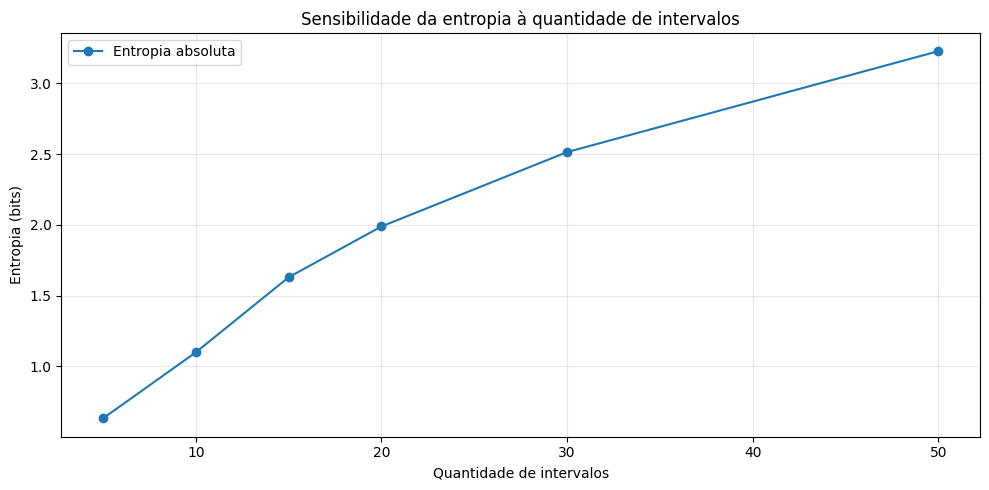

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    sensibilidade["Quantidade_Bins"],
    sensibilidade["Entropia_bits"],
    marker="o",
    label="Entropia absoluta"
)

ax.set_title("Sensibilidade da entropia à quantidade de intervalos")
ax.set_xlabel("Quantidade de intervalos")
ax.set_ylabel("Entropia (bits)")
ax.grid(alpha=0.3)

ax.legend()
plt.tight_layout()
plt.show()

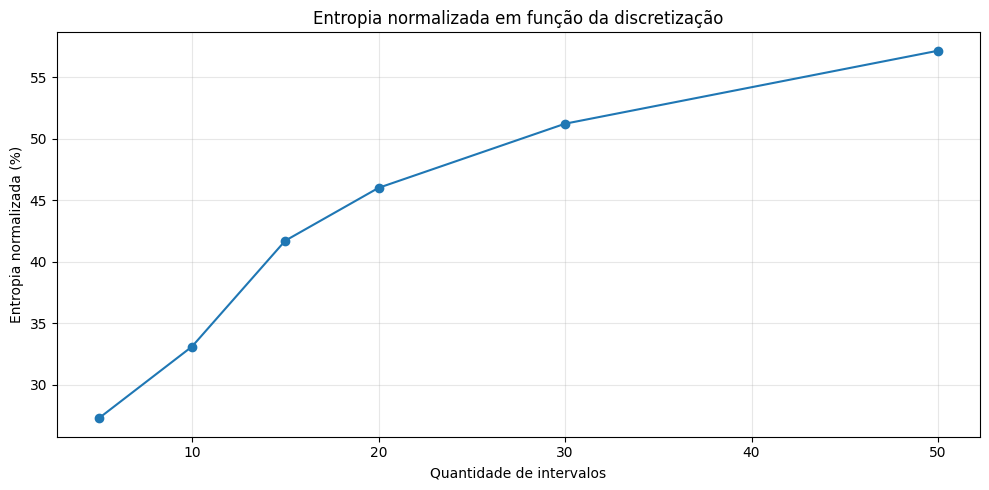

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    sensibilidade["Quantidade_Bins"],
    sensibilidade["Entropia_normalizada"] * 100,
    marker="o"
)

ax.set_title("Entropia normalizada em função da discretização")
ax.set_xlabel("Quantidade de intervalos")
ax.set_ylabel("Entropia normalizada (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análise de sensibilidade à quantidade de intervalos

Para investigar a influência da discretização sobre a entropia de Shannon, foram realizados cálculos utilizando diferentes quantidades de intervalos: 5, 10, 15, 20, 30 e 50.

Os resultados demonstraram um aumento progressivo da entropia absoluta, que passou de 0,632939 bits, com cinco intervalos, para 3,227095 bits, com cinquenta intervalos.

A entropia normalizada também apresentou crescimento, passando de aproximadamente 27,26% para 57,18% do máximo teórico correspondente a cada discretização.

Esse comportamento indica que a quantidade de intervalos influencia não apenas o limite máximo da entropia, mas também a distribuição relativa das probabilidades entre as categorias.

Com uma quantidade maior de intervalos, a representação dos retornos torna-se mais detalhada, permitindo distinguir variações que anteriormente pertenciam à mesma categoria.

Entretanto, o aumento da resolução também pode produzir categorias com poucas observações, tornando as estimativas mais sensíveis às características específicas da amostra.

Dessa forma, os resultados evidenciam que a entropia de Shannon, quando aplicada a uma variável contínua discretizada, depende dos parâmetros utilizados na construção dos intervalos.

Consequentemente, a comparação entre valores de entropia deve considerar a quantidade de categorias e o procedimento de discretização adotado.

In [9]:
numero_bins = 10

freq_width, limites_width = np.histogram(
    retornos,
    bins=numero_bins
)

prob_width = freq_width / len(retornos)

p_width_validas = prob_width[prob_width > 0]

entropia_width = -np.sum(
    p_width_validas * np.log2(p_width_validas)
)

distribuicao_width = pd.DataFrame({
    "Intervalo_Inferior": limites_width[:-1],
    "Intervalo_Superior": limites_width[1:],
    "Frequencia": freq_width,
    "Probabilidade": prob_width
})

display(distribuicao_width)

print(f"Entropia Equal Width: {entropia_width:.6f} bits")

,Intervalo_Inferior,Intervalo_Superior,Frequencia,Probabilidade
0,-0.159930,-0.130915,3,0.001019
1,-0.130915,-0.101900,2,0.000679
2,-0.101900,-0.072884,2,0.000679
3,-0.072884,-0.043869,9,0.003056
4,-0.043869,-0.014854,287,0.097453
5,-0.014854,0.014162,2246,0.762649
6,0.014162,0.043177,382,0.129711
7,0.043177,0.072192,10,0.003396
8,0.072192,0.101208,3,0.001019
9,0.101208,0.130223,1,0.000340


Entropia Equal Width: 1.099535 bits


In [10]:
numero_bins = 10

retornos_quantile, limites_quantile = pd.qcut(
    retornos,
    q=numero_bins,
    labels=False,
    retbins=True,
    duplicates="drop"
)

freq_quantile = (
    retornos_quantile
    .value_counts()
    .sort_index()
)

prob_quantile = freq_quantile / len(retornos)

entropia_quantile = -np.sum(
    prob_quantile * np.log2(prob_quantile)
)

distribuicao_quantile = pd.DataFrame({
    "Intervalo": freq_quantile.index,
    "Intervalo_Inferior": limites_quantile[:-1],
    "Intervalo_Superior": limites_quantile[1:],
    "Frequencia": freq_quantile.values,
    "Probabilidade": prob_quantile.values
})

display(distribuicao_quantile)

print(f"Entropia Quantile: {entropia_quantile:.6f} bits")
print("Quantidade de intervalos:", len(freq_quantile))

,Intervalo,Intervalo_Inferior,Intervalo_Superior,Frequencia,Probabilidade
0,0,-0.159930,-0.015068,295,0.10017
1,1,-0.015068,-0.008967,294,0.09983
2,2,-0.008967,-0.005045,295,0.10017
3,3,-0.005045,-0.002145,294,0.09983
4,4,-0.002145,0.000496,295,0.10017
5,5,0.000496,0.003557,294,0.09983
6,6,0.003557,0.006375,294,0.09983
7,7,0.006375,0.010444,295,0.10017
8,8,0.010444,0.016344,294,0.09983
9,9,0.016344,0.130223,295,0.10017


Entropia Quantile: 3.321926 bits
Quantidade de intervalos: 10


In [11]:
comparacao = pd.DataFrame({
    "Metodo": [
        "Equal Width",
        "Quantile Binning"
    ],
    "Quantidade_Intervalos": [
        len(freq_width),
        len(freq_quantile)
    ],
    "Entropia_bits": [
        entropia_width,
        entropia_quantile
    ],
    "Entropia_Maxima": [
        np.log2(len(freq_width)),
        np.log2(len(freq_quantile))
    ],
    "Entropia_Normalizada": [
        entropia_width / np.log2(len(freq_width)),
        entropia_quantile / np.log2(len(freq_quantile))
    ]
})

display(comparacao)

,Metodo,Quantidade_Intervalos,Entropia_bits,Entropia_Maxima,Entropia_Normalizada
0,Equal Width,10,1.099535,3.321928,0.330993
1,Quantile Binning,10,3.321926,3.321928,0.999999


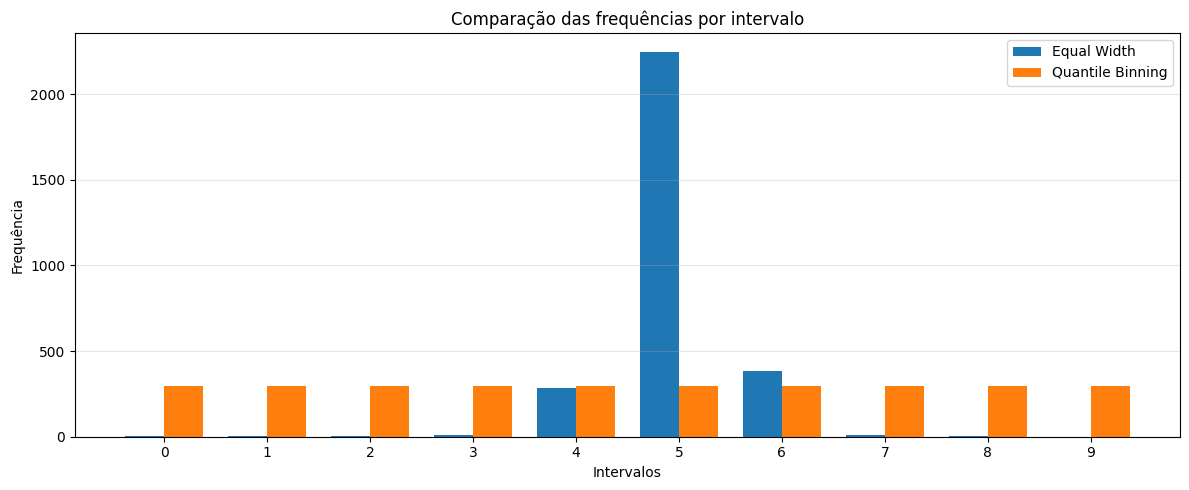

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

indices = np.arange(numero_bins)
largura = 0.38

ax.bar(
    indices - largura/2,
    freq_width,
    largura,
    label="Equal Width"
)

ax.bar(
    indices + largura/2,
    freq_quantile.values,
    largura,
    label="Quantile Binning"
)

ax.set_title("Comparação das frequências por intervalo")
ax.set_xlabel("Intervalos")
ax.set_ylabel("Frequência")
ax.set_xticks(indices)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

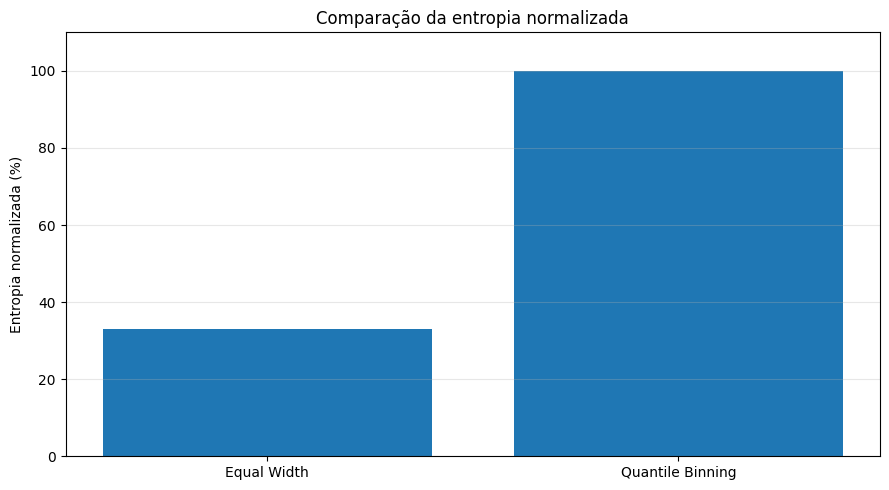

In [13]:
metodos = ["Equal Width", "Quantile Binning"]

entropias = [
    entropia_width / np.log2(len(freq_width)),
    entropia_quantile / np.log2(len(freq_quantile))
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(metodos, np.array(entropias) * 100)

ax.set_title("Comparação da entropia normalizada")
ax.set_ylabel("Entropia normalizada (%)")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
larguras_quantile = np.diff(limites_quantile)

analise_quantile = pd.DataFrame({
    "Intervalo": range(len(larguras_quantile)),
    "Limite_Inferior": limites_quantile[:-1],
    "Limite_Superior": limites_quantile[1:],
    "Largura": larguras_quantile,
    "Frequencia": freq_quantile.values
})

display(analise_quantile)

print(
    "Largura mínima:",
    larguras_quantile.min()
)

print(
    "Largura máxima:",
    larguras_quantile.max()
)

,Intervalo,Limite_Inferior,Limite_Superior,Largura,Frequencia
0,0,-0.159930,-0.015068,0.144862,295
1,1,-0.015068,-0.008967,0.006101,294
2,2,-0.008967,-0.005045,0.003922,295
3,3,-0.005045,-0.002145,0.002900,294
4,4,-0.002145,0.000496,0.002641,295
5,5,0.000496,0.003557,0.003061,294
6,6,0.003557,0.006375,0.002818,294
7,7,0.006375,0.010444,0.004069,295
8,8,0.010444,0.016344,0.005900,294
9,9,0.016344,0.130223,0.113879,295


Largura mínima: 0.002640553525588697
Largura máxima: 0.14486219881500154


In [15]:
# Validação do método Equal Width
assert freq_width.sum() == len(retornos)
assert np.isclose(prob_width.sum(), 1)
assert 0 <= entropia_width <= np.log2(len(freq_width))

# Validação do método Quantile Binning
assert freq_quantile.sum() == len(retornos)
assert np.isclose(prob_quantile.sum(), 1)
assert 0 <= entropia_quantile <= np.log2(len(freq_quantile))

print("Validações concluídas com sucesso!")

print("\nEqual Width:")
print(f"Observações: {freq_width.sum()}")
print(f"Soma das probabilidades: {prob_width.sum():.6f}")
print(f"Entropia: {entropia_width:.6f} bits")

print("\nQuantile Binning:")
print(f"Observações: {freq_quantile.sum()}")
print(f"Soma das probabilidades: {prob_quantile.sum():.6f}")
print(f"Entropia: {entropia_quantile:.6f} bits")

Validações concluídas com sucesso!

Equal Width:
Observações: 2945
Soma das probabilidades: 1.000000
Entropia: 1.099535 bits

Quantile Binning:
Observações: 2945
Soma das probabilidades: 1.000000
Entropia: 3.321926 bits


## 6. Validações e limitações

### Validações

Foram realizadas verificações para garantir a consistência dos cálculos de entropia nos dois métodos de discretização.

Os resultados confirmaram que:

- Ambos os métodos utilizaram as 2.945 observações disponíveis.
- A soma das probabilidades foi igual a 1.
- As entropias calculadas respeitaram os limites matemáticos estabelecidos.
- O número de intervalos utilizado foi consistente com os cálculos da entropia máxima.

### Limitações

Apesar dos resultados consistentes, existem algumas limitações metodológicas:

1. **Dependência da discretização:** a entropia calculada depende da quantidade e da estratégia de construção dos intervalos. Diferentes escolhas podem produzir valores significativamente distintos.

2. **Perda de informação:** a discretização transforma retornos contínuos em categorias, reduzindo a precisão das informações originais.

3. **Ausência de informação temporal:** o cálculo considera a distribuição dos retornos, mas não preserva a ordem cronológica das observações. Assim, não identifica diretamente dependências temporais ou agrupamentos de volatilidade.

4. **Sensibilidade a valores extremos:** retornos muito distantes da região central podem ampliar consideravelmente os intervalos, especialmente no método Quantile Binning.

5. **Interpretação da entropia:** valores maiores não representam necessariamente maior risco, volatilidade ou imprevisibilidade do mercado. A interpretação depende do método de discretização e das características da distribuição analisada.

## 7. Conclusão

A análise da entropia financeira permitiu investigar a distribuição dos retornos logarítmicos do Ibovespa por meio da entropia de Shannon.

Inicialmente, utilizando o método Equal Width com 10 intervalos, foi obtida uma entropia de **1,099535 bits**, correspondente a aproximadamente **33,10% da entropia máxima**. Esse resultado está relacionado à concentração das observações em determinadas faixas, principalmente no intervalo central, que concentrou aproximadamente 76,26% dos retornos.

Na análise de sensibilidade, observou-se que o aumento da quantidade de intervalos elevou os valores da entropia absoluta e normalizada, demonstrando que a escolha dos parâmetros de discretização influencia diretamente os resultados.

Posteriormente, a comparação com o método Quantile Binning produziu uma entropia de **3,321926 bits**, praticamente igual à entropia máxima de 3,321928 bits. Esse comportamento decorre da distribuição aproximadamente uniforme das frequências entre os intervalos, característica própria desse método.

A comparação demonstrou que diferentes estratégias de discretização podem produzir interpretações distintas sobre a distribuição dos retornos. Portanto, a entropia deve ser analisada considerando as escolhas metodológicas utilizadas, não sendo suficiente, isoladamente, para caracterizar risco, volatilidade ou previsibilidade do mercado.

Conclui-se que a entropia de Shannon constitui uma ferramenta complementar para a análise estatística e financeira, especialmente quando utilizada em conjunto com outras medidas de distribuição, volatilidade e dependência temporal.